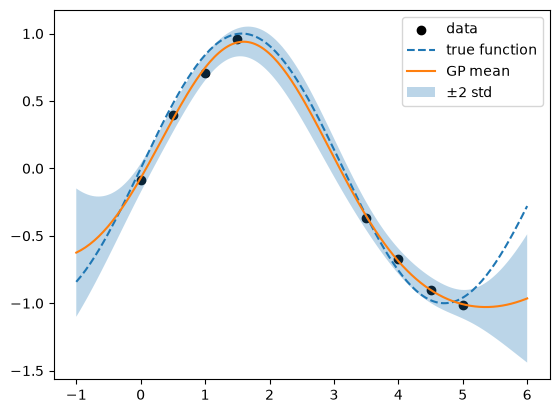

RBF(length_scale=1.56) + WhiteKernel(noise_level=0.00304)


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel

# 1. Training data: sin(x) plus noise, with a gap between 1.5 and 3.5
x_train = np.array([0, 0.5, 1, 1.5, 3.5, 4, 4.5, 5])
y_train = np.sin(x_train) + np.random.normal(0, 0.1, size=len(x_train))
#         ↑ sin of every x at once   ↑ a little noise on each point

# 2. Build the model
kernel = RBF() + WhiteKernel()  # smooth function + noisy data
gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True)

# 3. Fit: sklearn needs X as a column (8 rows, 1 feature)
gp.fit(x_train.reshape(-1, 1), y_train)

# 4. Predict mean and uncertainty at 200 points
x_test = np.linspace(-1, 6, 200)
mean, std = gp.predict(x_test.reshape(-1, 1), return_std=True)

# 5. Plot
plt.scatter(x_train, y_train, color="black", label="data")
plt.plot(x_test, np.sin(x_test), "--", label="true function")
plt.plot(x_test, mean, label="GP mean")
plt.fill_between(x_test, mean - 2 * std, mean + 2 * std, alpha=0.3, label="±2 std")
plt.legend()
plt.show()

print(gp.kernel_)